# 1. Generación de datos sintéticos y exploración (EDA)
**RetailNova — Caso 1 (SCY1102 Gestión de Proyectos de Datos, Sección 001D)** · Hurtubia · Pacheco · Curi · Gómez

Genera la base histórica de 3 años (185.000 clientes, abandono ≈ 24 % según el caso) y la muestra de los últimos 12 meses sobre la que se trabaja el resto del proyecto. Luego explora la muestra con 5 gráficos, cada uno con su justificación.

Toda la lógica vive en `src/generador_dataset.py`; el cuaderno la ejecuta y muestra los resultados. Semilla fija (42) para que el resultado sea reproducible.

## 1.1 Configuración

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as cfg

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

## 1.2 Generación de la base histórica y recorte a 12 meses
El generador simula región/comuna (sobre-representando la Región Metropolitana, como indica el caso), edad, canal, hábitos de compra, reclamos, devoluciones y marketing. El abandono se define por probabilidad (reclamos, devoluciones, promociones, canal) y se calibra a ≈ 24 %; luego se vuelve coherente con la regla de negocio: **abandono = más de 180 días sin comprar**. También se simulan nulos (≈ 8 % en variables demográficas) para emular un dataset real con problemas de calidad.

Como los 185.000 clientes son un acumulado de 3 años, se recorta a los clientes activos o que abandonaron en los últimos 12 meses desde la fecha de corte (2026-09-30).

In [2]:
from src.generador_dataset import generar
historica, muestra = generar()

Generando 185,000 clientes sintéticos (semilla 42)...


Base histórica (3 años): 185,000 filas · abandono 24.0%
Muestra 12 meses:        51,346 filas · abandono 24.0%
Nulos en la muestra: {'edad': 2039, 'comuna': 2080, 'canal_compra': 525, 'monto_promedio_compra': 1070}


In [3]:
print("Base histórica (3 años):", historica.shape, "· abandono", f"{historica['abandono'].mean():.1%}")
print("Muestra 12 meses:", muestra.shape, "· abandono", f"{muestra['abandono'].mean():.1%}")
muestra.head()

Base histórica (3 años): (185000, 17) · abandono 24.0%
Muestra 12 meses: (51346, 17) · abandono 24.0%


,id_cliente,edad,comuna,region,fecha_registro,canal_compra,cantidad_compras,frecuencia_compra,monto_promedio_compra,monto_total_acumulado,categorias_productos,uso_promociones,devoluciones,reclamos,interacciones_marketing,fecha_ultima_compra,abandono
8,CL000009,33.000,Puente Alto,Metropolitana,2026-06-03,E-commerce,1,0.230,"229,500.000","229,500.000",Hogar,0,0,0,3,2026-02-19,1
10,CL000011,27.000,Maipú,Metropolitana,2026-03-20,Tienda física,2,0.350,"40,500.000","81,000.000","Electrodomésticos, Tecnología",0,1,0,4,2026-01-31,1
26,CL000027,49.000,Las Condes,Metropolitana,2026-06-23,E-commerce,1,0.420,"18,200.000","18,200.000","Electrodomésticos, Hogar",0,0,0,3,2026-07-12,0
28,CL000029,40.000,Las Condes,Metropolitana,2026-06-12,Tienda física,3,0.830,"19,800.000","59,400.000",Tecnología,1,0,0,4,2026-07-21,0
30,CL000031,18.000,Villa Alemana,Valparaíso,2026-07-18,Tienda física,1,0.590,"121,600.000","121,600.000",Hogar,0,0,0,5,2026-07-26,0


## 1.3 Calidad de partida de la muestra
Los nulos son intencionales: se tratan en el cuaderno 02.

In [4]:
pd.DataFrame({"Nulos": muestra.isnull().sum(), "%": (muestra.isnull().mean()*100).round(2)}).query("Nulos > 0")

,Nulos,%
edad,2039,3.970
comuna,2080,4.050
canal_compra,525,1.020
monto_promedio_compra,1070,2.080


# Análisis exploratorio (EDA) — muestra de 12 meses

### Gráfico 1 · Distribución de la variable objetivo
**Por qué:** confirmar el desbalance típico de churn (≈ 24 % abandona) y justificar que la métrica de evaluación sea recall/F1 y no accuracy.

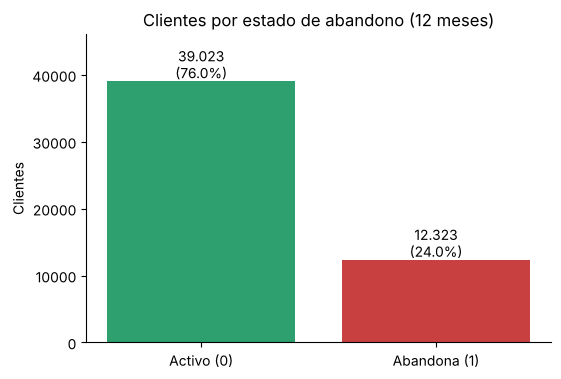

In [5]:
conteo = muestra["abandono"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Activo (0)", "Abandona (1)"], conteo.values, color=["#2E9F6E", "#C94040"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}".replace(",", ".") + f"\n({v/conteo.sum():.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max()*1.18); ax.set_ylabel("Clientes"); ax.set_title("Clientes por estado de abandono (12 meses)")
plt.show()

### Gráfico 2 · Clientes por región
**Por qué:** verificar el sesgo geográfico del caso (RM sobre-representada), que obliga a evaluar el modelo por región (RNF6).

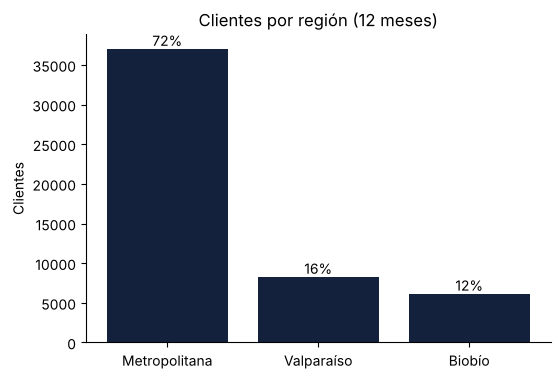

In [6]:
reg = muestra["region"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(reg.index, reg.values, color="#14213D")
for i, v in enumerate(reg.values):
    ax.text(i, v, f"{v/reg.sum():.0%}", ha="center", va="bottom")
ax.set_ylabel("Clientes"); ax.set_title("Clientes por región (12 meses)")
plt.show()

### Gráfico 3 · Edad según abandono
**Por qué:** ver si quienes abandonan son sistemáticamente más jóvenes o mayores y detectar valores atípicos de edad.

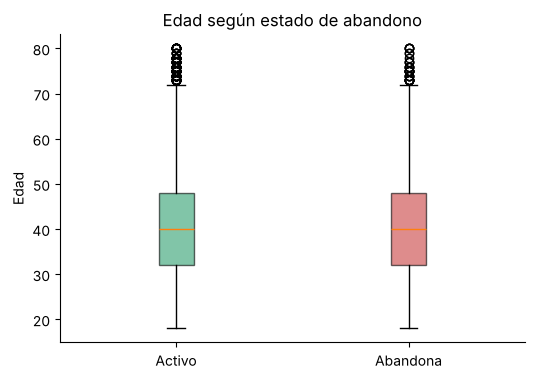

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
datos = [muestra.loc[muestra["abandono"] == k, "edad"].dropna() for k in (0, 1)]
bp = ax.boxplot(datos, tick_labels=["Activo", "Abandona"], patch_artist=True)
for caja, c in zip(bp["boxes"], ["#2E9F6E", "#C94040"]): caja.set_facecolor(c); caja.set_alpha(.6)
ax.set_ylabel("Edad"); ax.set_title("Edad según estado de abandono")
plt.show()

### Gráfico 4 · Tasa de abandono según reclamos
**Por qué:** cuantifica el efecto de una mala experiencia en la retención y ayuda a definir una alerta temprana.

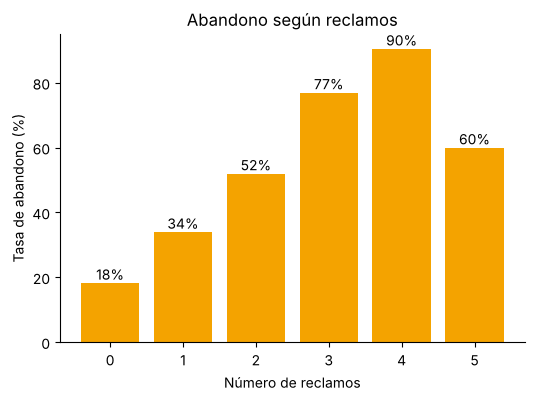

In [8]:
t = muestra.groupby("reclamos")["abandono"].mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(t.index.astype(str), t.values*100, color="#F4A300")
for i, v in enumerate(t.values): ax.text(i, v*100, f"{v:.0%}", ha="center", va="bottom")
ax.set_xlabel("Número de reclamos"); ax.set_ylabel("Tasa de abandono (%)"); ax.set_title("Abandono según reclamos")
plt.show()

### Gráfico 5 · Tasa de abandono según canal de compra
**Por qué:** compara la propensión al abandono entre canal digital, presencial y mixto; insumo directo para campañas de fidelización.

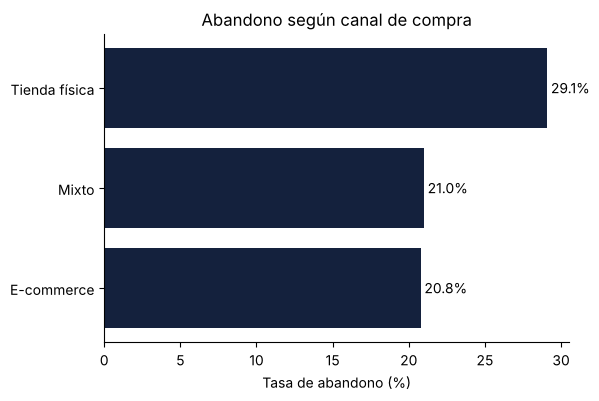

In [9]:
t = muestra.groupby("canal_compra")["abandono"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(t.index, t.values*100, color="#14213D")
for i, v in enumerate(t.values): ax.text(v*100, i, f" {v:.1%}", va="center")
ax.set_xlabel("Tasa de abandono (%)"); ax.set_title("Abandono según canal de compra")
plt.show()

**Siguiente:** `02_preparacion_de_datos.ipynb`.